# Task 2

Este notebook contiene únicamente los Tasks 2.1–2.4. Extiende el motor de eventos de task_1_3_corregido.py; los archivos originales del Task 1 se conservan intactos. Es autónomo: no necesita importar archivos del Task 1.

Ejecución: Python 3 con NumPy, pandas, SciPy y Matplotlib. Las simulaciones ya se ejecutaron y se conservan sus resultados. Las celdas de experimentos reproducen el código utilizado; Ejecutar todo vuelve a simular y puede tardar varios minutos. Los IC se construyen con una observación por réplica.

Parámetros: $g=4$, $\lambda=3.6$ pacientes/día, $\mu=0.25$ por día, $c=17$ camas, $a=14.4$ Erlangs, $\rho=0.8471$ y $k_{off}=6$ camas. El cierre dura siete días.

Alcance: se trata de un ejercicio de simulación con los supuestos de la hoja, sin calibración con datos reales del hospital.

## Preparación del simulador

Se conservan la lista de eventos futuros (heapq), la fila FCFS (deque), los promedios ponderados por tiempo y el seguimiento completo de todos los pacientes medidos. Las nuevas opciones son la distribución de estancia y los eventos de cierre y reapertura.

Supuesto del cierre: no se interrumpe la atención de pacientes que ya ocupan cama. Cuando la capacidad baja a 11, pueden permanecer temporalmente más de 11 hospitalizados, pero no se inicia ninguna estancia hasta que la ocupación sea menor que la capacidad. Esto representa la retirada de camas conforme se liberan. Una clausura física inmediata con traslado de ocupantes requeriría otra regla, que la hoja no especifica.

Los flujos de llegadas y estancias se separan para que cambiar la distribución no cambie las llegadas. Entre experimentos comparables se usan las mismas semillas; dentro de cada experimento las réplicas son independientes. Las comparaciones entre distribuciones no se tratan como muestras independientes.

In [1]:
"""Extensión del motor de task_1_3_corregido.py, sin modificar el archivo original."""
import heapq
import math
import random
from collections import deque

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt


def erlang_b(c, a):
    b = 1.0
    for j in range(1, c + 1):
        b = a * b / (j + a * b)
    return b


def teoria_mm(lam, mu, c):
    a = lam / mu
    rho = a / c
    if rho >= 1:
        raise ValueError('La variante con espera requiere rho < 1.')
    b = erlang_b(c, a)
    C = b / (1 - rho + rho * b)
    wq = C / (c * mu - lam)
    return dict(B=b, C=C, Lq=lam * wq, Wq_hours=24*wq, rho=rho)


def simulate_hospital(lam, mu, c, horizon, warmup, seed, waiting=True,
                      distribution='exponencial', sample_every=None,
                      closure=None, split_streams=True, interarrival=None,
                      fixed_service=None):

    if not (lam > 0 and mu > 0 and c >= 1 and 0 <= warmup < horizon):
        raise ValueError('Parámetros inválidos.')
    if distribution not in ('determinista', 'exponencial', 'lognormal'):
        raise ValueError('Distribución desconocida.')
    if sample_every is not None and sample_every <= 0:
        raise ValueError('sample_every debe ser positivo.')
    if closure:
        t0, Tb, koff = closure
        if not (warmup < t0 < t0 + Tb < horizon and 0 < koff < c):
            raise ValueError('Cierre inválido.')
    if split_streams:
        master = random.Random(seed)
        rng_arr = random.Random(master.getrandbits(128))
        rng_srv = random.Random(master.getrandbits(128))
    else:
        rng_arr = rng_srv = random.Random(seed)
    mean_service = 1 / mu
    s2 = math.log(5)  # CS=2 -> var(log S)=ln(1+CS²)
    m = math.log(mean_service) - s2 / 2
    def arrival_time():
        return interarrival if interarrival is not None else rng_arr.expovariate(lam)
    def service_time():
        if fixed_service is not None:
            return fixed_service
        if distribution == 'determinista':
            return mean_service
        if distribution == 'lognormal':
            return rng_srv.lognormvariate(m, math.sqrt(s2))
        return rng_srv.expovariate(mu)

    events, queue, samples = [], deque(), []
    counter = 0
    def schedule(t, kind, info=None):
        nonlocal counter
        heapq.heappush(events, (t, counter, kind, info))
        counter += 1
    schedule(arrival_time(), 'arrival')
    if closure:
        schedule(t0, 'close')
        schedule(t0 + Tb, 'open')
    capacity = c
    busy = arrivals = admitted = blocked = waited = wait_count = sojourn_count = 0
    wait_sum = sojourn_sum = area_system = area_queue = area_busy = area_capacity = 0.0
    t_prev = next_sample = 0.0
    def start(t, patient):
        nonlocal busy, wait_count, wait_sum
        busy += 1
        assert busy <= capacity, 'Se inició servicio sin cama disponible.'
        if patient[1]:
            wait_count += 1
            wait_sum += t - patient[0]
        schedule(t + service_time(), 'departure', patient)
    def fill(t):
        while queue and busy < capacity:
            start(t, queue.popleft())

    while events:
        t, _, kind, info = heapq.heappop(events)
        end, left = min(t, horizon), max(t_prev, warmup)
        if end > left:
            dt = end - left
            area_system += (busy + len(queue)) * dt
            area_queue += len(queue) * dt
            area_busy += busy * dt
            area_capacity += capacity * dt
        if sample_every is not None:
            while next_sample <= end + 1e-10:
                samples.append((next_sample, len(queue), busy + len(queue)))
                next_sample += sample_every
        t_prev = end
        if kind == 'arrival':
            if t >= horizon:
                continue
            schedule(t + arrival_time(), 'arrival')
            patient = (t, t >= warmup)
            measured = patient[1]
            arrivals += int(measured)
            if busy < capacity:
                admitted += int(measured)
                start(t, patient)
            elif waiting:
                queue.append(patient)
                waited += int(measured)
                admitted += int(measured)
            else:
                blocked += int(measured)
        elif kind == 'departure':
            if info[1]:
                sojourn_sum += t - info[0]
                sojourn_count += 1
            busy -= 1
            fill(t)
        elif kind == 'close':
            capacity = c - koff
        elif kind == 'open':
            capacity = c
            fill(t)
    assert busy == 0 and not queue
    assert wait_count == admitted == sojourn_count
    observed = horizon - warmup
    out = dict(L=area_system/observed, Lq=area_queue/observed,
               Wq_hours=24*wait_sum/wait_count if wait_count else float('nan'),
               W_hours=24*sojourn_sum/sojourn_count if sojourn_count else float('nan'),
               utilization=area_busy/area_capacity,
               prob_wait=waited/arrivals if arrivals else float('nan'),
               prob_block=blocked/arrivals if arrivals else float('nan'),
               lambda_ef=admitted/observed, arrivals=arrivals, admitted=admitted,
               blocked=blocked)
    if sample_every is not None:
        out['trayectoria'] = np.asarray(samples)
    return out


def replica_seeds(n, master_seed):
    rng = random.Random(master_seed)
    seeds = []
    while len(seeds) < n:
        seed = rng.getrandbits(128)
        if seed not in seeds:
            seeds.append(seed)
    return seeds


def ic95(xs):
    xs = np.asarray(xs, dtype=float)
    if len(xs) < 2 or not np.isfinite(xs).all():
        raise ValueError('El IC requiere al menos dos réplicas finitas.')
    avg = float(xs.mean())
    half = float(stats.t.ppf(.975, len(xs)-1) * xs.std(ddof=1) / math.sqrt(len(xs)))
    return dict(media=avg, semiancho=half, inferior=avg-half, superior=avg+half)


def replicas(n, master_seed, **kwargs):
    return [simulate_hospital(seed=s, **kwargs) for s in replica_seeds(n, master_seed)]


def primer_cruce(t, q, reopening, threshold):
    ix = np.flatnonzero((t >= reopening) & (q < threshold))
    return float(t[ix[0]] - reopening) if len(ix) else float('nan')


## Pruebas de respuesta conocida antes de usar la extensión.

In [2]:
# 1. D/D/1 sin fila: llega cada 3 d, estancia 1 d; ventana [3,300).
# Se observan 99 servicios completos en 297 días: L=99/297=1/3.
r = simulate_hospital(1/3, 1, 1, 300, 3, 7,
                      interarrival=3, fixed_service=1)
assert abs(r['L'] - 1/3) < 1e-12
assert r['Wq_hours'] == 0
print('PASA: D/D/1 sin fila, L = 1/3 y Wq = 0.')

# 2. D/D/1 sobrecargado: llegadas t=1,...,9, horizonte excluye t=10.
# Esperas 0, 0.5,...,4 d -> media 2 d, incluso si terminan después del horizonte.
r = simulate_hospital(1, 1, 1, 10, 0, 7,
                      interarrival=1, fixed_service=1.5)
assert r['admitted'] == 9 and abs(r['Wq_hours']/24 - 2) < 1e-12
print('PASA: seguimiento al horizonte, 9 pacientes y Wq = 2 d.')

# 3. Dos camas, llegadas cada 1 d y estancia 3 d. Se cierra una cama
# en [4,6) y se observa hasta 6.1. Inicios: 1,2,5,6,8,9.
# Esperas: 0,0,2,2,3,3 -> 10/6 d. Área cola: 1+2+2+0.2=5.2.
r = simulate_hospital(1, 1/3, 2, 6.1, 0, 7, closure=(4,2,1),
                      interarrival=1, fixed_service=3)
assert abs(r['Wq_hours']/24 - 10/6) < 1e-12
assert abs(r['Lq'] - 5.2/6.1) < 1e-12
print('PASA: cierre no preemptivo y reapertura inmediata, Wq = 40 h.')

# 4. El generador de semillas no repite ninguna dentro del experimento.
assert len(set(replica_seeds(5000, 240230))) == 5000
print('PASA: semillas distintas y reproducibles.')


PASA: D/D/1 sin fila, L = 1/3 y Wq = 0.
PASA: seguimiento al horizonte, 9 pacientes y Wq = 2 d.
PASA: cierre no preemptivo y reapertura inmediata, Wq = 40 h.
PASA: semillas distintas y reproducibles.


Además de estas pruebas, se comparó la extensión con el archivo original del Task 1.3 usando su mismo flujo aleatorio, semilla 42, horizonte 3,000 días y calentamiento 100 días. Las dos variantes reprodujeron todas las métricas comunes con diferencia menor que $10^{-10}$.

In [3]:
base = dict(lam=3.6, mu=.25, c=17)
teo = teoria_mm(**base)
resultados = {'teoria': teo, 'estancias': {}, 'cierre': {}}
raw = {}
pd.set_option('display.precision', 4)
print('Parámetros lognormales: m =', math.log(4)-math.log(5)/2,
      '; s =', math.sqrt(math.log(5)))
print('Lq estacionario M/M/17 =', teo['Lq'])


Parámetros lognormales: m = 0.5815754049028404 ; s = 1.2686362411795196
Lq estacionario M/M/17 = 2.2807871444300774


## Task 2.2 — Distribución de la estancia

Se implementan $S=4$ días, $S\sim\mathrm{Exp}(0.25)$ y $S=\exp(m+sZ)$, con $Z\sim N(0,1)$, $s^2=\ln5$ y $m=\ln4-\ln5/2$. Así, en los tres casos $E[S]=4$, y en la lognormal $C_S^2=e^{s^2}-1=4$.

Se usan 30 réplicas por distribución, horizonte 15,000 días y calentamiento 1,000 días; se observan 14,000 días por réplica. Se amplía la configuración del Task 1 para reducir la incertidumbre de la lognormal, cuyas estancias y esperas son más variables. El calentamiento es conservador respecto al del caso exponencial validado, aunque no constituye por sí solo una prueba de estabilización del caso lognormal.

Cada réplica aporta su media de espera, incluyendo los ceros de quienes entraron directamente. El IC del 95 % es 
$\bar x\pm t_{29,0.975}s/\sqrt{30}$.
 
Se define el error de la aproximación usando la media simulada como referencia. El IC expresa incertidumbre de Monte Carlo, no incertidumbre sobre los supuestos del modelo.

In [4]:
for dist, factor in [('determinista',.5), ('exponencial',1), ('lognormal',2.5)]:
    print('Estancia:', dist, flush=True)
    rr = replicas(30, 240210, **base, horizon=15000, warmup=1000, distribution=dist)
    w = ic95([x['Wq_hours'] for x in rr])
    w['prediccion'] = teo['Wq_hours'] * factor
    w['error_rel_pct'] = 100*abs(w['prediccion']-w['media'])/w['media']
    w['Lq'] = ic95([x['Lq'] for x in rr])
    resultados['estancias'][dist] = w
    raw['estancia_'+dist] = np.array([[x['Wq_hours'],x['Lq']] for x in rr])
    print(w,flush=True)

Estancia: determinista
{'media': 8.246583128186188, 'semiancho': 0.19778315082363568, 'inferior': 8.048799977362552, 'superior': 8.444366279009824, 'prediccion': 7.6026238147669245, 'error_rel_pct': 7.8088015776893105, 'Lq': {'media': 1.237530227797844, 'semiancho': 0.03096904445969147, 'inferior': 1.2065611833381524, 'superior': 1.2684992722575354}}
Estancia: exponencial
{'media': 15.216803445905889, 'semiancho': 0.7904254148369454, 'inferior': 14.426378031068943, 'superior': 16.007228860742835, 'prediccion': 15.205247629533849, 'error_rel_pct': 0.07594115553321971, 'Lq': {'media': 2.283790359872646, 'semiancho': 0.12015206422391529, 'inferior': 2.163638295648731, 'superior': 2.4039424240965612}}
Estancia: lognormal
{'media': 29.925620118981858, 'semiancho': 2.3301556864535256, 'inferior': 27.59546443252833, 'superior': 32.255775805435384, 'prediccion': 38.01311907383462, 'error_rel_pct': 27.025334555132094, 'Lq': {'media': 4.491672520591859, 'semiancho': 0.3527129504474963, 'inferior

,Estancia,Predicción (h),Simulación (h),IC 95 % inferior,IC 95 % superior,Error relativo (%)
0,determinista,7.6026,8.2466,8.0488,8.4444,7.8088
1,exponencial,15.2052,15.2168,14.4264,16.0072,0.0759
2,lognormal,38.0131,29.9256,27.5955,32.2558,27.0253


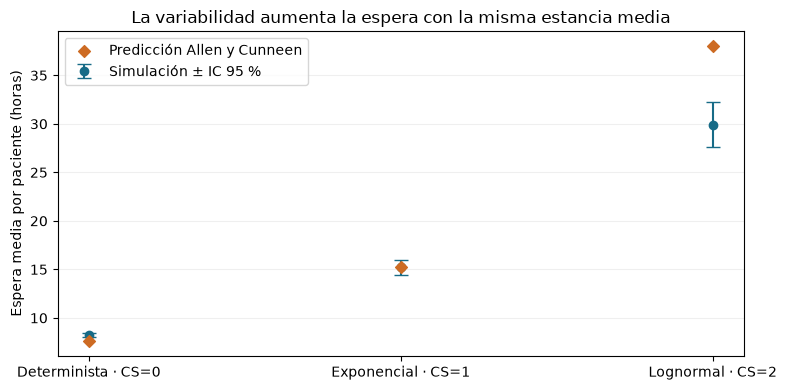

In [5]:
filas = []
for dist, d in resultados['estancias'].items():
    filas.append({'Estancia':dist, 'Predicción (h)':d['prediccion'],
                  'Simulación (h)':d['media'], 'IC 95 % inferior':d['inferior'],
                  'IC 95 % superior':d['superior'], 'Error relativo (%)':d['error_rel_pct']})
tabla_22 = pd.DataFrame(filas)
display(tabla_22)

fig, ax = plt.subplots(figsize=(8,4))
xx = np.arange(3)
ax.errorbar(xx, tabla_22['Simulación (h)'],
            yerr=[resultados['estancias'][d]['semiancho'] for d in resultados['estancias']],
            fmt='o', capsize=5, color='#176b87', label='Simulación ± IC 95 %')
ax.scatter(xx, tabla_22['Predicción (h)'], marker='D', color='#cd6b23',
           label='Predicción Allen y Cunneen', zorder=3)
ax.set_xticks(xx, ['Determinista · CS=0','Exponencial · CS=1','Lognormal · CS=2'])
ax.set_ylabel('Espera media por paciente (horas)')
ax.set_title('La variabilidad aumenta la espera con la misma estancia media')
ax.grid(axis='y',alpha=.2); ax.legend(); fig.tight_layout(); plt.show()


## Task 2.3 — Cierre parcial y recuperación

Se simulan 5,000 réplicas con cierre entre los días 300 y 307, calentamiento 100 días y horizonte 450 días. La observación de la trayectoria se hace cada 0.25 días. Se repite el experimento con estancia exponencial y determinista, junto con controles sin cierre con las mismas semillas. La determinista se usa para explorar cuánto cambia la recuperación al eliminar la variabilidad de la estancia; las llegadas continúan siendo Poisson.

Se promedia primero entre réplicas: $\overline Q(t)=R^{-1}\sum_r Q_r(t)$. La recuperación se define exactamente como el primer instante muestreado posterior a la reapertura en que $\overline Q(t)<1.1L_q^{est}$. No se promedian tiempos de vaciado individuales.

Para la exponencial, $L_q^{est}=2.280787$ y el umbral es 2.508866. Para la determinista, se estima su propia fila estacionaria mediante el control sin cierre en los días [100,300). Usar el umbral exponencial para ambos modelos se presenta aparte como análisis de sensibilidad.

El promedio principal no se suaviza. Se escogen más de las 100 réplicas mínimas porque el primer cruce de un umbral cercano a la meseta es sensible al ruido.

In [6]:
N, t0, Tb, dt, horizon = 5000, 300, 7, .25, 450
for dist in ['exponencial','determinista']:
    qs, controles = [], []
    print('Cierre:', dist, flush=True)
    for i, seed in enumerate(replica_seeds(N,240230)):
        params = dict(**base, horizon=horizon, warmup=100, seed=seed,
                      distribution=dist, sample_every=dt)
        r = simulate_hospital(**params, closure=(t0,Tb,6))
        ctrl = simulate_hospital(**params)
        t = r['trayectoria'][:,0]
        qs.append(r['trayectoria'][:,1])
        controles.append(ctrl['trayectoria'][:,1])
        if (i+1)%1000==0:
            print('  réplicas',i+1,flush=True)
    qs, controles = np.array(qs), np.array(controles)
    qmean, control = qs.mean(axis=0), controles.mean(axis=0)
    pre = (t >=100) & (t <t0)
    lq = teo['Lq'] if dist=='exponencial' else float(control[pre].mean())
    th = 1.1*lq
    recovery = primer_cruce(t,qmean,t0+Tb,th)
    common = primer_cruce(t,qmean,t0+Tb,1.1*teo['Lq'])
    grupos = np.array_split(qs,5)
    cruces_bloques = [primer_cruce(t,g.mean(axis=0),t0+Tb,th) for g in grupos]
    raw['q_'+dist]=qs
    raw['control_'+dist]=controles
    raw['t']=t
    resultados['cierre'][dist]=dict(n=N,t0=t0,Tb=Tb,dt=dt,horizon=horizon,
        Lq_base=lq,umbral=th,recuperacion=recovery,
        recuperacion_umbral_comun=common,cruces_bloques=cruces_bloques,
        cola_reapertura=float(qmean[np.flatnonzero(t==t0+Tb)[0]]),
        cola_antes=float(qmean[np.flatnonzero(t==t0)[0]]),
        control_Lq=ic95(controles[:,pre].mean(axis=1)),
        ultimo_promedio=float(qmean[t>430].mean()))
    print(resultados['cierre'][dist],flush=True)



Cierre: exponencial
  réplicas 1000
  réplicas 2000
  réplicas 3000
  réplicas 4000
  réplicas 5000
{'n': 5000, 't0': 300, 'Tb': 7, 'dt': 0.25, 'horizon': 450, 'Lq_base': 2.2807871444300774, 'umbral': 2.508865858873085, 'recuperacion': 50.5, 'recuperacion_umbral_comun': 50.5, 'cruces_bloques': [70.25, 49.5, 50.5, 49.25, 39.75], 'cola_reapertura': 11.3228, 'cola_antes': 2.3158, 'control_Lq': {'media': 2.2816690000000004, 'semiancho': 0.05875217143118648, 'inferior': 2.222916828568814, 'superior': 2.3404211714311867}, 'ultimo_promedio': 2.24382}
Cierre: determinista
  réplicas 1000
  réplicas 2000
  réplicas 3000
  réplicas 4000
  réplicas 5000
{'n': 5000, 't0': 300, 'Tb': 7, 'dt': 0.25, 'horizon': 450, 'Lq_base': 1.2262047500000002, 'umbral': 1.3488252250000003, 'recuperacion': 28.25, 'recuperacion_umbral_comun': 8.25, 'cruces_bloques': [32.25, 28.25, 28.25, 24.25, 32.25], 'cola_reapertura': 8.3104, 'cola_antes': 1.2248, 'control_Lq': {'media': 1.22620475, 'semiancho': 0.021962248512466

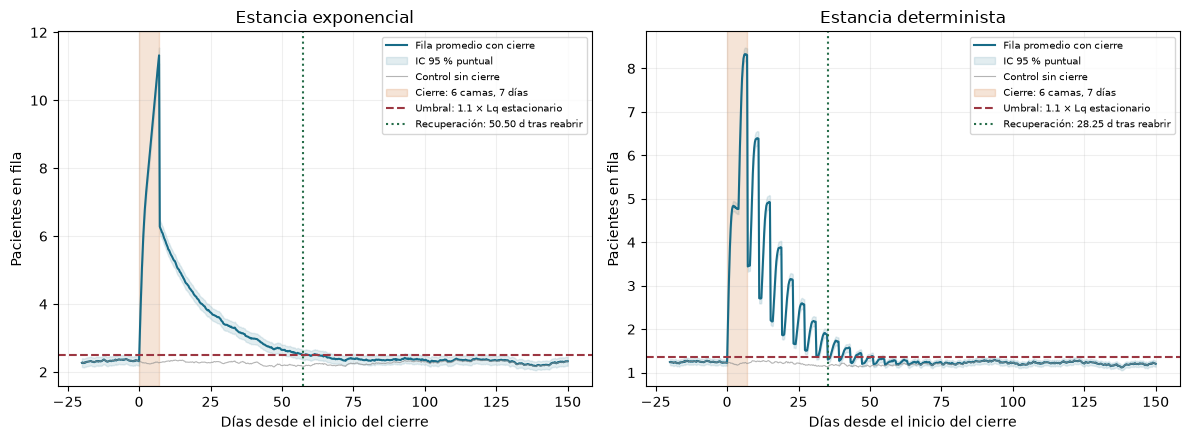

,Estancia,Réplicas,Lq estacionario,Umbral propio,Fila al reabrir,Recuperación (d),Con umbral común (d),Cruces de 5 bloques de 1000
0,exponencial,5000,2.2808,2.5089,11.3228,50.50,50.50,"[70.25, 49.5, 50.5, 49.25, 39.75]"
1,determinista,5000,1.2262,1.3488,8.3104,28.25,8.25,"[32.25, 28.25, 28.25, 24.25, 32.25]"


In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
t = raw['t']
for ax, dist, title in zip(axes, ['exponencial','determinista'],
                           ['Estancia exponencial','Estancia determinista']):
    d = resultados['cierre'][dist]
    mat = raw['q_'+dist]
    mean = mat.mean(axis=0)
    control = raw['control_'+dist].mean(axis=0)
    half = stats.t.ppf(.975,len(mat)-1)*mat.std(axis=0,ddof=1)/math.sqrt(len(mat))
    rel = t - d['t0']
    keep = rel >= -20
    ax.plot(rel[keep],mean[keep],color='#176b87',label='Fila promedio con cierre')
    ax.fill_between(rel[keep],(mean-half)[keep],(mean+half)[keep],
                    color='#176b87',alpha=.12,label='IC 95 % puntual')
    ax.plot(rel[keep],control[keep],color='0.55',alpha=.65,lw=.8,label='Control sin cierre')
    ax.axvspan(0,7,color='#cd6b23',alpha=.18,label='Cierre: 6 camas, 7 días')
    ax.axhline(d['umbral'],color='#9c3742',ls='--',label='Umbral: 1.1 × Lq estacionario')
    ax.axvline(7+d['recuperacion'],color='#256d49',ls=':',
               label=f"Recuperación: {d['recuperacion']:.2f} d tras reabrir")
    ax.set(title=title,xlabel='Días desde el inicio del cierre',ylabel='Pacientes en fila')
    ax.grid(alpha=.2); ax.legend(fontsize=7.5)
fig.tight_layout(); plt.show()

filas=[]
for dist,d in resultados['cierre'].items():
    filas.append({'Estancia':dist,'Réplicas':d['n'], 'Lq estacionario':d['Lq_base'],
                  'Umbral propio':d['umbral'],'Fila al reabrir':d['cola_reapertura'],
                  'Recuperación (d)':d['recuperacion'],
                  'Con umbral común (d)':d['recuperacion_umbral_comun'],
                  'Cruces de 5 bloques de 1000':str(d['cruces_bloques'])})
tabla_23=pd.DataFrame(filas)
display(tabla_23)


## Task 2.4 — Estancia más larga y balance de predicciones

Se simula M/M/17/17 con estancia exponencial media de 5 días, es decir, $\mu'=0.20$ por día. Se mantienen las llegadas en 3.6 pacientes/día. Se usan exactamente 30 réplicas, horizonte 15,000 y calentamiento 1,000 días. Cada réplica aporta su proporción de bloqueo; el IC se construye sobre esas 30 proporciones.

In [8]:
rr=replicas(30,240240,lam=3.6,mu=.2,c=17,horizon=15000,warmup=1000,waiting=False)
b=ic95([x['prob_block'] for x in rr])
b['prediccion']=erlang_b(17,18)
b['error_rel_pct']=100*abs(b['prediccion']-b['media'])/b['media']
b['factor_actual']=b['media']/teo['B']
resultados['bloqueo']=b
raw['bloqueo']=np.array([x['prob_block'] for x in rr])
print(b,flush=True)

{'media': 0.20045761250963962, 'semiancho': 0.0016249397901706402, 'inferior': 0.19883267271946897, 'superior': 0.20208255229981026, 'prediccion': 0.1997178745762436, 'error_rel_pct': 0.36902461529638586, 'factor_actual': 2.0725231337104693}


In [9]:
b = resultados['bloqueo']
display(pd.DataFrame([{
    'Bloqueo actual teórico (%)':100*teo['B'],
    'Predicción con estancia 5 d (%)':100*b['prediccion'],
    'Simulación (%)':100*b['media'],
    'IC 95 % inferior (%)':100*b['inferior'],
    'IC 95 % superior (%)':100*b['superior'],
    'Factor simulado / bloqueo actual teórico':b['factor_actual'],
    'Teoría dentro del IC':b['inferior'] <= b['prediccion'] <= b['superior']
}]))

filas=[]
for dist,d in resultados['estancias'].items():
    filas.append({'Predicción':f'2.1a: {dist}',
                  'Valor predicho':f"{d['prediccion']:.2f} h",
                  'Resultado simulado (IC 95 %)':f"{d['media']:.2f} ± {d['semiancho']:.2f} h",
                  'Error relativo (%)':d['error_rel_pct'],
                  'Explicación':{'determinista':'La aproximación subestima; no es exacta para M/D/c.',
                    'exponencial':'La teoría exacta está dentro del IC; diferencia de Monte Carlo.',
                    'lognormal':'La aproximación sobreestima y no representa exactamente la cola lognormal.'}[dist]})
td = 5.95/.65
tr = resultados['cierre']['exponencial']['recuperacion']
filas.append({'Predicción':'2.1b: recuperación tras cierre',
              'Valor predicho':f'{td:.2f} d; simulación mayor',
              'Resultado simulado (IC 95 %)':f'{tr:.2f} d; sin IC de recuperación',
              'Error relativo (%)':100*abs(td-tr)/tr,
              'Explicación':'Se acertó la dirección. El modelo lineal omite variabilidad, frontera en cero y criterio de meseta.'})
filas.append({'Predicción':'2.1c: bloqueo con estancia 5 d',
              'Valor predicho':f"{100*b['prediccion']:.2f} %; factor {b['prediccion']/teo['B']:.2f}",
              'Resultado simulado (IC 95 %)':f"{100*b['media']:.2f} ± {100*b['semiancho']:.2f} %; factor {b['factor_actual']:.2f}",
              'Error relativo (%)':b['error_rel_pct'],
              'Explicación':'Erlang B queda dentro del IC; la discrepancia es compatible con Monte Carlo.'})
tabla_balance=pd.DataFrame(filas)
display(tabla_balance)


,Bloqueo actual teórico (%),Predicción con estancia 5 d (%),Simulación (%),IC 95 % inferior (%),IC 95 % superior (%),Factor simulado / bloqueo actual teórico,Teoría dentro del IC
0,9.6722,19.9718,20.0458,19.8833,20.2083,2.0725,True


,Predicción,Valor predicho,Resultado simulado (IC 95 %),Error relativo (%),Explicación
0,2.1a: determinista,7.60 h,8.25 ± 0.20 h,7.8088,La aproximación subestima; no es exacta para M...
1,2.1a: exponencial,15.21 h,15.22 ± 0.79 h,0.0759,La teoría exacta está dentro del IC; diferenci...
2,2.1a: lognormal,38.01 h,29.93 ± 2.33 h,27.0253,La aproximación sobreestima y no representa ex...
3,2.1b: recuperación tras cierre,9.15 d; simulación mayor,50.50 d; sin IC de recuperación,81.8736,Se acertó la dirección. El modelo lineal omite...
4,2.1c: bloqueo con estancia 5 d,19.97 %; factor 2.06,20.05 ± 0.16 %; factor 2.07,0.3690,Erlang B queda dentro del IC; la discrepancia ...
